In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
import kagglehub
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt

/kaggle/input/competitions/store-sales-time-series-forecasting/oil.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/sample_submission.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/holidays_events.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/stores.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/train.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/test.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/transactions.csv


In [2]:
data_path = Path('/kaggle/input/competitions/store-sales-time-series-forecasting')

files = list(data_path.glob('*.csv'))

dataframes = {}

for file in files:
    name = file.stem
    dataframes[name] = pd.read_csv(file)

# Check file
for name, df in dataframes.items():
    print(name, df.shape)

oil (1218, 2)
sample_submission (28512, 2)
holidays_events (350, 6)
stores (54, 5)
train (3000888, 6)
test (28512, 5)
transactions (83488, 3)


In [3]:
def inspect_dataset(df, name):
    print(f'\n---{name}---')
    print(f'Rows: {df.shape[0]} --- Cols: {df.shape[1]}')

    print(f'\nData Types:')
    display(df.dtypes.to_frame(name='Data Type'))

    print(f'\nMissing Values:')
    missing = df.isna().sum()
    display(missing[missing > 0].to_frame(name='Missing Vales'))

In [4]:
inspect_dataset(dataframes['train'], 'Train')
inspect_dataset(dataframes['test'], 'Test')


---Train---
Rows: 3000888 --- Cols: 6

Data Types:


,Data Type
id,int64
date,object
store_nbr,int64
family,object
sales,float64
onpromotion,int64



Missing Values:


,Missing Vales



---Test---
Rows: 28512 --- Cols: 5

Data Types:


,Data Type
id,int64
date,object
store_nbr,int64
family,object
onpromotion,int64



Missing Values:


,Missing Vales


In [5]:
for df in dataframes.values():
    if 'date' in df.columns:
        df['date'] = pd.to_datetime(df['date'])

# Exploratoy Analysis

In [6]:
# Check metrics of train set
dataframes['train']['sales'].describe()

count    3.000888e+06
mean     3.577757e+02
std      1.101998e+03
min      0.000000e+00
25%      0.000000e+00
50%      1.100000e+01
75%      1.958473e+02
max      1.247170e+05
Name: sales, dtype: float64

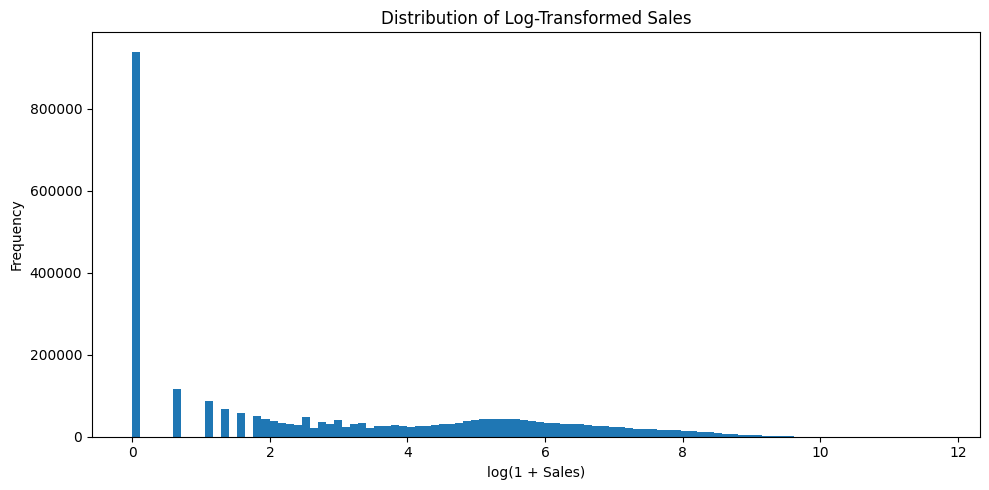

In [7]:
sales = dataframes['train']['sales']

plt.figure(figsize=(10, 5))
plt.hist(np.log1p(sales), bins=100)

plt.title('Distribution of Log-Transformed Sales')
plt.xlabel('log(1 + Sales)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

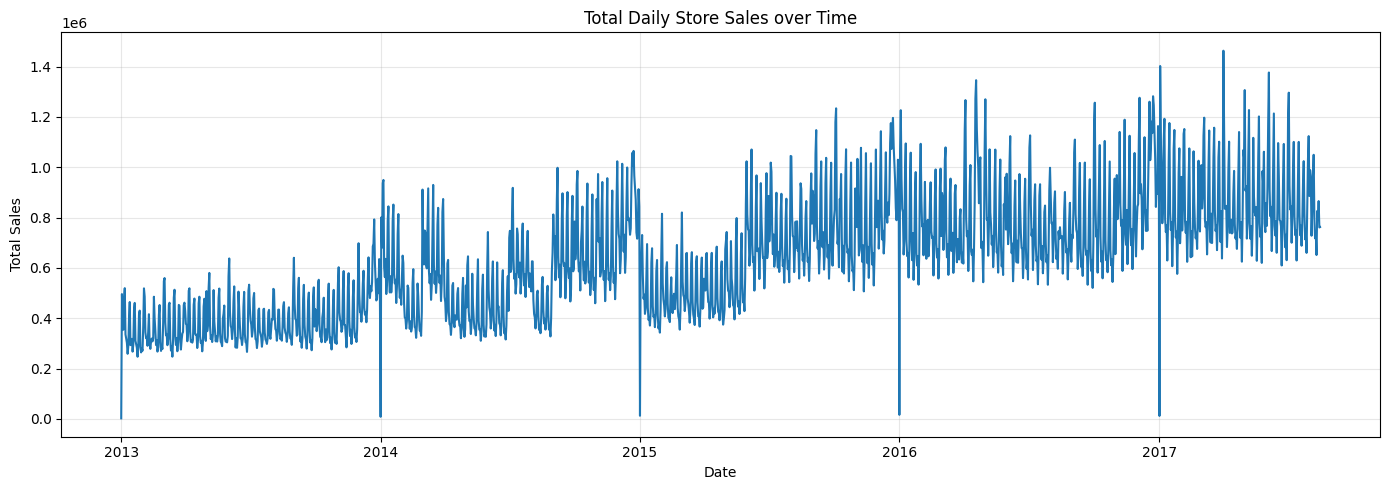

In [8]:
# Sales Distribution over time
daily_sales = dataframes['train'].groupby('date')['sales'].sum()
plt.figure(figsize=(14, 5))
plt.plot(daily_sales.index, daily_sales.values)
plt.title('Total Daily Store Sales over Time')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()